# Machine Learning in Python - Project 

Due Friday, December 4th 2026, by 4 pm.

**Include contributors names here!**

## Setup

*Install any packages here, define any functions if needed, and load data.*

In [2]:
# Add any additional libraries or submodules below

# Data libraries
import pandas as pd
import numpy as np

# Plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn modules
import sklearn

In [3]:
# Load data  
df_avg = pd.read_csv("avg_river_levels.csv")
df_min = pd.read_csv("min_river_levels.csv")
df_max = pd.read_csv("max_river_levels.csv")
df_locs = pd.read_csv("monitoring_locations.csv")


In [ ]:

df_avg.head()

,County,Station_Name,Observation_ID,05/10/2014,06/10/2014,07/10/2014,08/10/2014,09/10/2014,10/10/2014,13/10/2014,...,29/09/2026,30/09/2026,01/10/2026,02/10/2026,03/10/2026,04/10/2026,05/10/2026,06/10/2026,07/10/2026,08/10/2026
0,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.133,0.152,0.169,0.143,0.136,0.130,0.126,0.120,0.120,0.120
1,aberdeenshire,"Dee (Grampian), Mar Lodge",aberdeenshire__dee-grampian-mar-lodge__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.721,0.971,0.849,0.799,0.861,0.752,0.727,0.695,0.677,0.669
2,aberdeenshire,"Dee (Grampian), Park",aberdeenshire__dee-grampian-park__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.934,0.973,1.264,0.990,1.054,0.988,0.918,0.887,0.854,0.836
3,aberdeenshire,"Dee (Grampian), Polhollick",aberdeenshire__dee-grampian-polhollick__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.483,0.704,0.683,0.530,0.676,0.530,0.496,0.460,0.438,0.427
4,aberdeenshire,"Dee (Grampian), Woodend",aberdeenshire__dee-grampian-woodend__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.578,0.700,0.861,0.645,0.739,0.642,0.583,0.547,0.514,0.495


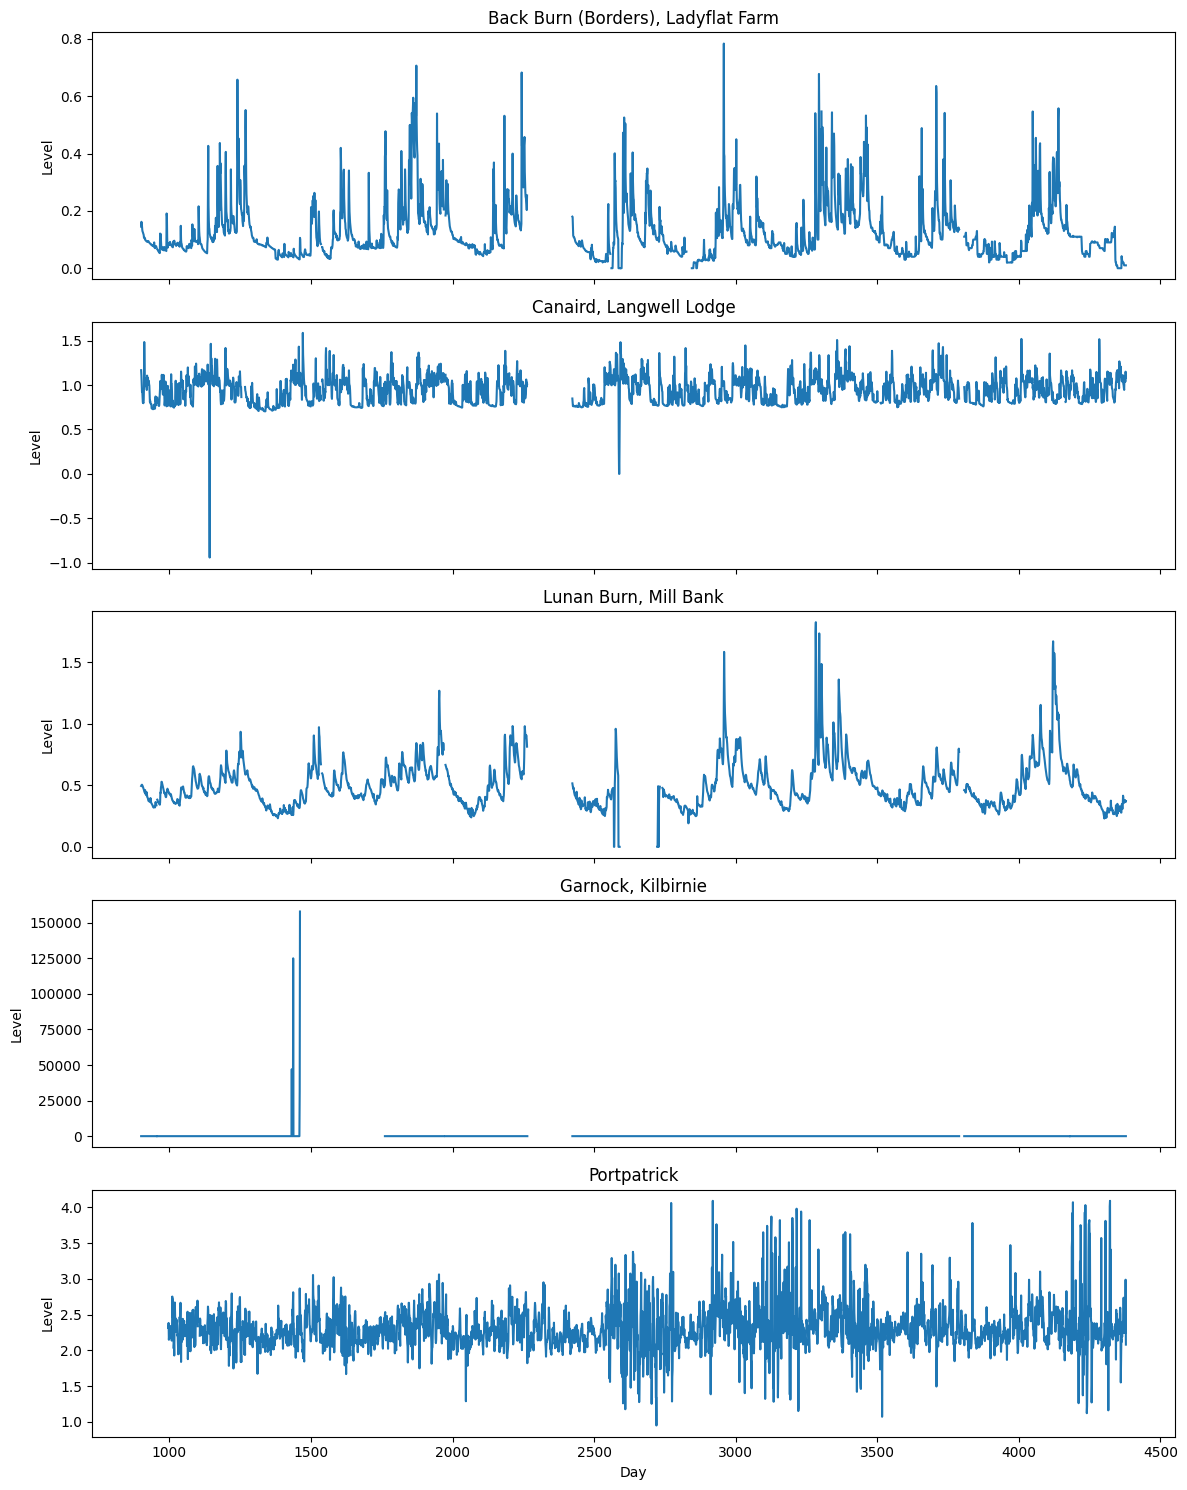

In [22]:
# Randomly sample 5 stations
sample = df_avg.sample(5, random_state=42)

fig, axes = plt.subplots(5, 1, figsize=(12, 15), sharex=True)

for ax, (_, row) in zip(axes, sample.iterrows()):

    ax.plot(row[level_cols].values)

    station = row.iloc[1]  # assuming second column is station name
    ax.set_title(station)
    ax.set_ylabel("Level")

plt.xlabel("Day")
plt.tight_layout()
plt.show()

In [11]:
station = df_avg[df_avg["Station_Name"] == "Garnock, Kilbirnie"]

values = station.iloc[:, 3:]  # all columns from the 3rd onwards

print("Mean:", values.mean(axis=1).iloc[0])
print("Min :", values.min(axis=1).iloc[0])
print("Max :", values.max(axis=1).iloc[0])
print("SD  :", values.std(axis=1).iloc[0])


Mean: 121.11276676676673
Min : -7.905
Max : 157895.392
SD  : 3819.3248192754995


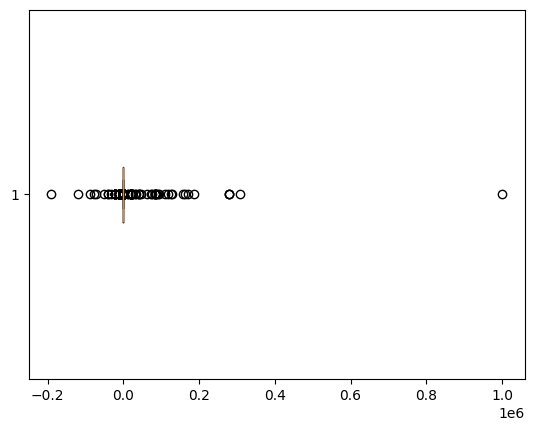

In [19]:

values = df_avg.iloc[:, 3:].apply(pd.to_numeric, errors="coerce")
all_values = values.to_numpy().flatten()

# Remove NaNs
all_values = all_values[~np.isnan(all_values)]

plt.boxplot(all_values, vert=False)
plt.show()

In [28]:
values = df_avg[level_cols].apply(pd.to_numeric, errors="coerce")
max_jumps = values.diff(axis=1).abs().max(axis=1)
result = pd.DataFrame({
    "Station": df_avg.iloc[:, 1],  # adjust if station name is elsewhere
    "MaxJump": max_jumps
})

print(
    result.sort_values("MaxJump", ascending=False)
          .head(25)
)

                                      Station     MaxJump
329           Endrick Water, Graystone Bridge  307692.247
379        Blackwater of Dee, Loch Dee Outlet  190476.430
61              Kilmarnock Water, Howard Park  170212.878
55                         Garnock, Kilbirnie  126644.568
182                            Spey, Spey Dam  119565.627
245          Leven (Fife), Loch Leven Sluices  118643.951
45   Annick Water, Chapeltoun Gauging Station  109589.052
134                  Loch Lomond, Ross Priory   91953.271
233                      Earn, Bridge of Earn   84210.491
121                          Nith, Whitesands   83333.418
170               Lochy (Lochaber), Gairlochy   76925.797
110             Esk (Solway), Langholm Bridge   62500.081
155              Dulnain, Inverlaidnan Bridge   41666.696
100                  Water of Leith, Colinton   41666.660
326            Duchray Water, Renagour Bridge   32257.952
335                        Loch Ard, Loch Ard   21978.000
241           

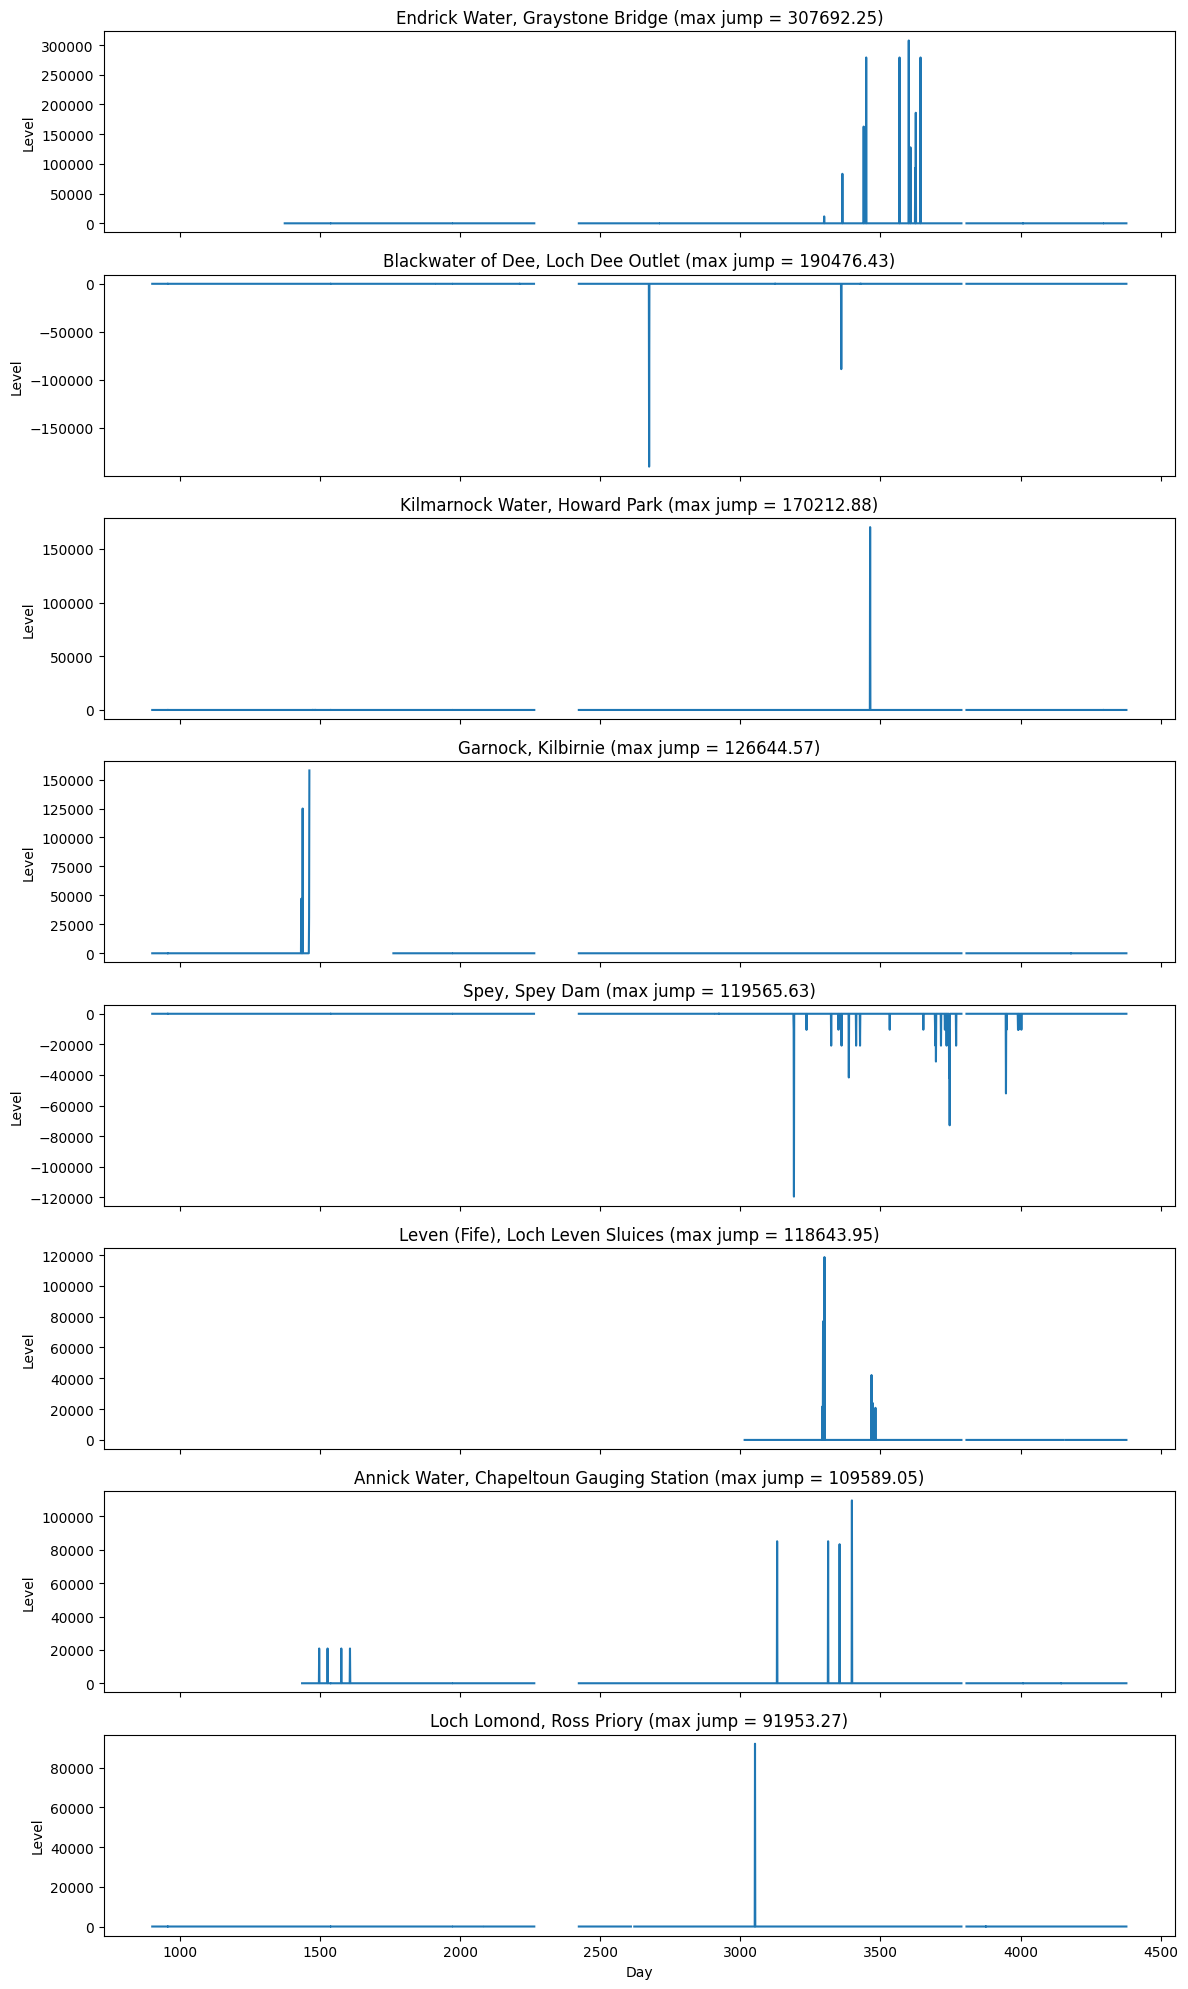

In [ ]:

top8_idx = max_jumps.nlargest(8).index

top8 = df_avg.loc[top8_idx]

fig, axes = plt.subplots(8, 1, figsize=(12, 20), sharex=True)

for ax, (_, row) in zip(axes, top8.iterrows()):

    y = pd.to_numeric(row[level_cols], errors="coerce")

    ax.plot(y.values)

    station = row.iloc[1]  # station name column
    jump = max_jumps.loc[row.name]

    ax.set_title(f"{station} (max jump = {jump:.2f})")
    ax.set_ylabel("Level")

plt.xlabel("Day")
plt.tight_layout()
plt.show()

In [15]:

values = df_avg.iloc[:, 3:].apply(pd.to_numeric, errors="coerce")

negative_counts = (values < 0).sum(axis=1)

stations_with_negatives = pd.DataFrame({
    "Station": df_avg.iloc[:, 1],  # adjust if station name is in another column
    "Negative_Count": (values < 0).sum(axis=1)
})

print(stations_with_negatives[stations_with_negatives["Negative_Count"] > 0])

                                  Station  Negative_Count
3              Dee (Grampian), Polhollick               2
5                        Deveron, Avochie               3
18               Brothock Water, Arbroath               1
26   North Esk (Tayside), Waterside Perth             365
28             South Esk (Angus), Brechin             708
..                                    ...             ...
377                                Bangor               3
378                                Bangor             706
379    Blackwater of Dee, Loch Dee Outlet               2
385                             Port Erin             485
388                           Portpatrick              74

[104 rows x 2 columns]


In [23]:
df_locs.head()

,County,Station_Name,Observation_ID,Latitude,Longitude
0,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,57.424758,-2.802015
1,aberdeenshire,"Dee (Grampian), Park",aberdeenshire__dee-grampian-park__obs1,57.075424,-2.335825
2,aberdeenshire,"Dee (Grampian), Polhollick",aberdeenshire__dee-grampian-polhollick__obs1,57.055146,-3.083181
3,aberdeenshire,"Dee (Grampian), Woodend",aberdeenshire__dee-grampian-woodend__obs1,57.050129,-2.603567
4,aberdeenshire,"Dee (Grampian), Mar Lodge",aberdeenshire__dee-grampian-mar-lodge__obs1,56.988040,-3.486198


<Axes: xlabel='Latitude', ylabel='Count'>

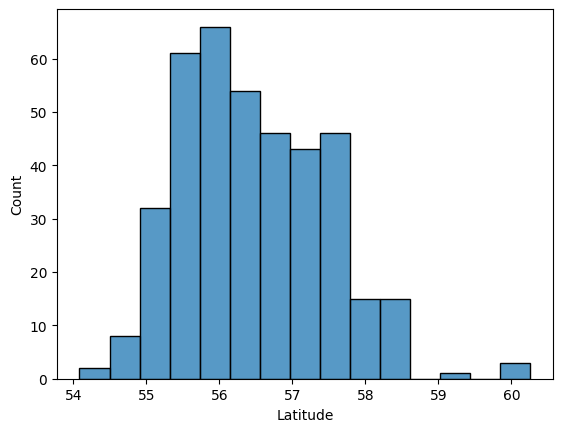

In [30]:
sns.histplot(data=df_locs,x= 'Latitude')

# Introduction

*This section should include a brief introduction to the task and the data (assume this is a report you are delivering to a professional body (e.g. Scottish Government)).*

*State which supervised learning question you are answering.*

*Briefly outline the approaches being used (for both the clustering and your chosen supervised learning task) and the conclusions that you are able to draw.*

# Exploratory Data Analysis and Feature Engineering

*Include a detailed discussion of the data with a particular emphasis on the features of the data that are relevant for the subsequent modeling. Including visualisations of the data is strongly encouraged - all code and plots must also be described in the write up. Think carefully about whether each plot needs to be included in your final draft and the appropriate type of plot and summary for each variable type - your report should include figures but they should be as focused and impactful as possible.*

*You should also split your data into training and testing sets, ideally before you look too much into the features and relationships with the target, as discussed throughout the course.*

*Additionally, this section should also motivate and describe any preprocessing / feature engineering of the data. Pipelines should be used, and feature engineering steps that are performed as part of an sklearn pipeline should be implemented in the following section.*

*All code and figures should be accompanied by text that provides an overview / context to what is being done or presented.*

In [31]:
df_avg.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 392 entries, 0 to 391
Columns: 4382 entries, County to 08/10/2026
dtypes: float64(4379), object(3)
memory usage: 13.1+ MB


In [32]:
df_min.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 392 entries, 0 to 391
Columns: 4382 entries, County to 08/10/2026
dtypes: float64(4379), object(3)
memory usage: 13.1+ MB


In [33]:
df_max.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 392 entries, 0 to 391
Columns: 4382 entries, County to 08/10/2026
dtypes: float64(4379), object(3)
memory usage: 13.1+ MB


In [34]:
df_locs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 392 entries, 0 to 391
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   County          392 non-null    object 
 1   Station_Name    392 non-null    object 
 2   Observation_ID  392 non-null    object 
 3   Latitude        392 non-null    float64
 4   Longitude       392 non-null    float64
dtypes: float64(2), object(3)
memory usage: 15.4+ KB


Missing Data

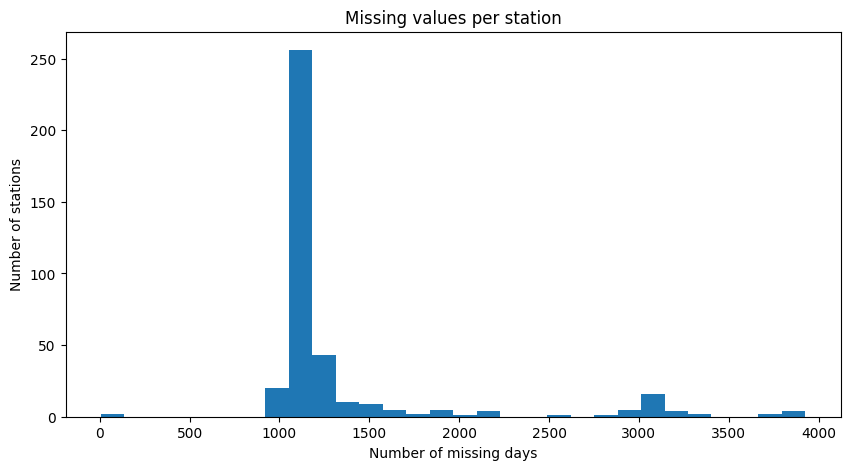

In [35]:
level_cols = df_avg.columns[3:]
na_by_station = (
    df_avg[level_cols]
    .isna()
    .sum(axis=1)
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
plt.hist(na_by_station, bins=30)
plt.xlabel("Number of missing days")
plt.ylabel("Number of stations")
plt.title("Missing values per station")
plt.show()

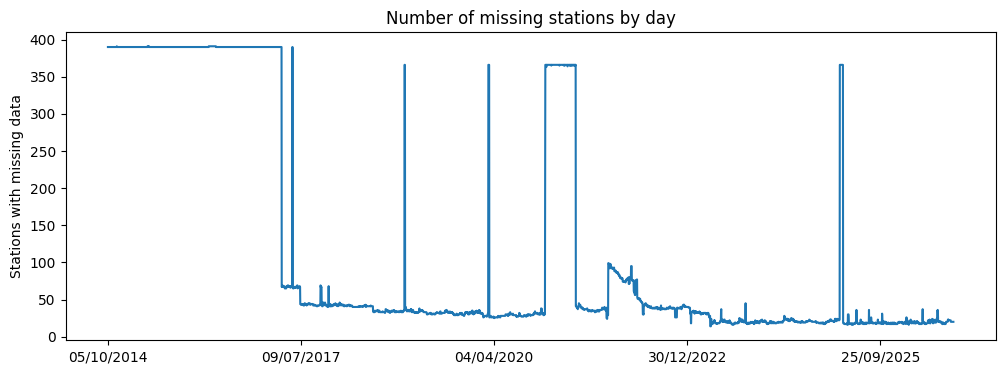

In [36]:
na_by_day = df_avg[level_cols].isna().sum(axis=0)

plt.figure(figsize=(12, 4))
na_by_day.plot()
plt.ylabel("Stations with missing data")
plt.title("Number of missing stations by day")
plt.show()

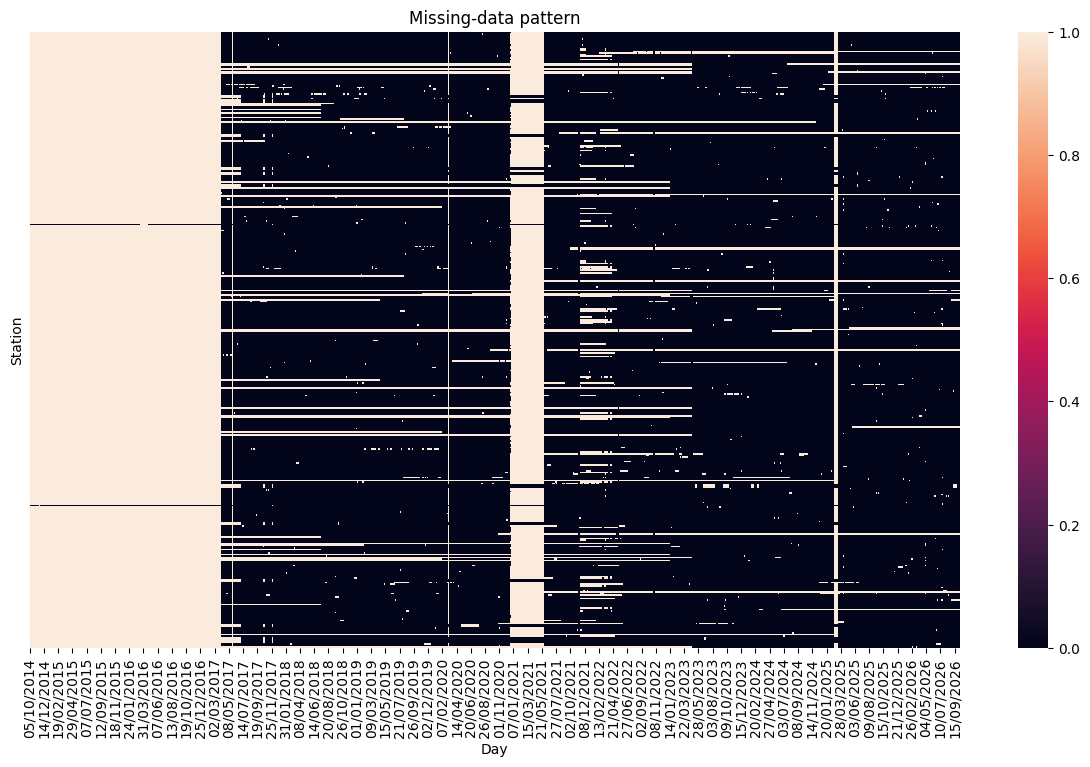

In [ ]:
plt.figure(figsize=(15,8))
sns.heatmap(df_avg[level_cols].isna(), cbar=True, yticklabels=False)
plt.xlabel("Day")
plt.ylabel("Station")
plt.title("Missing-data pattern")
plt.show()

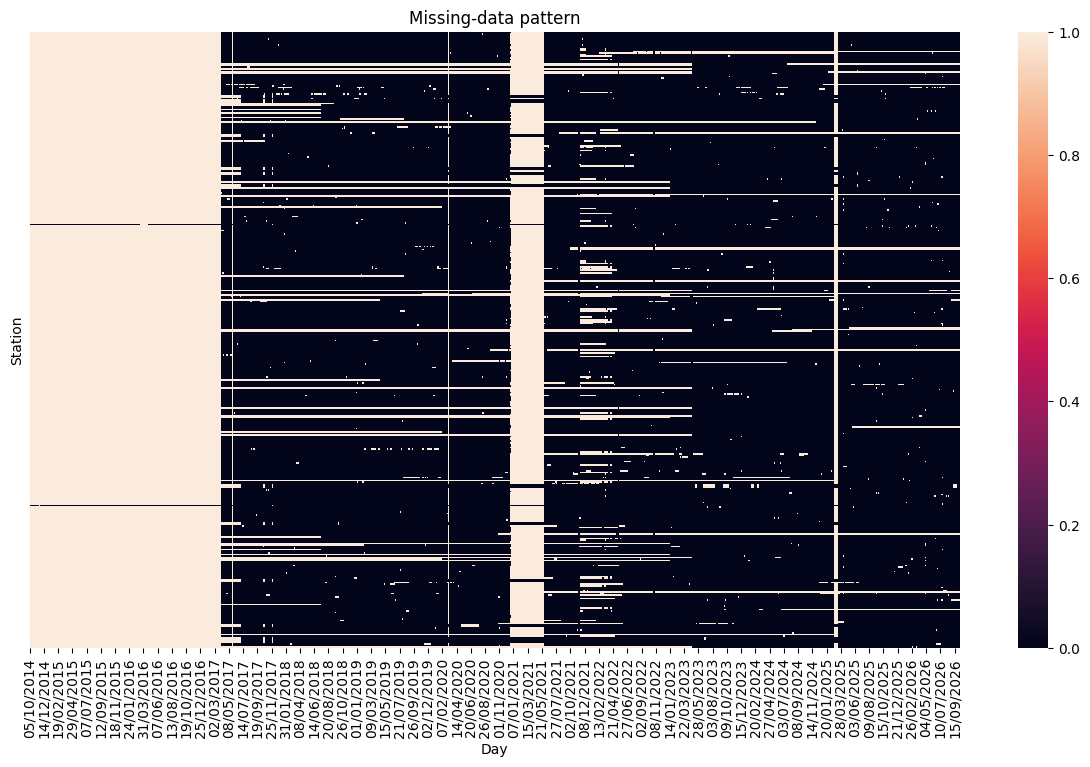

In [ ]:
plt.figure(figsize=(15,8))
sns.heatmap(df_min[level_cols].isna(), cbar=True, yticklabels=False)
plt.xlabel("Day")
plt.ylabel("Station")
plt.title("Missing-data pattern")
plt.show()

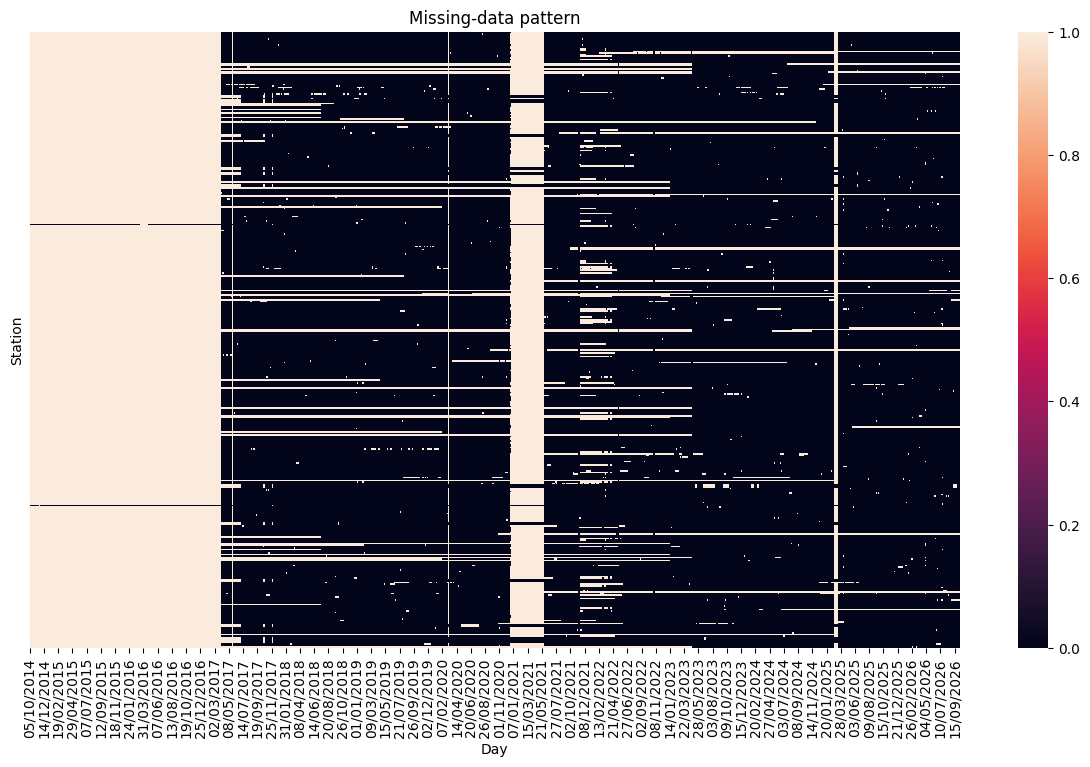

In [ ]:
plt.figure(figsize=(15,8))
sns.heatmap(df_max[level_cols].isna(), cbar=True, yticklabels=False)
plt.xlabel("Day")
plt.ylabel("Station")
plt.title("Missing-data pattern")
plt.show()

In [52]:
dates = pd.to_datetime(level_cols, dayfirst=True)
coverage = df_avg[level_cols].notna().mean(axis=0)
keep_dates = coverage[coverage >= 0.1].index
df_avg_clean = pd.concat([df_avg.iloc[:, :3], df_avg[keep_dates]], axis=1)
df_min_clean = pd.concat([df_min.iloc[:, :3], df_min[keep_dates]], axis=1)
df_max_clean = pd.concat([df_max.iloc[:, :3], df_max[keep_dates]], axis=1)
df_avg_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 392 entries, 0 to 391
Columns: 3297 entries, County to 08/10/2026
dtypes: float64(3294), object(3)
memory usage: 9.9+ MB


In [ ]:
levels = df_avg_clean.iloc[:, 3:]

def longest_nan_run(row):
    mask = row.isna()
    run = max_run = 0
    for x in mask:
        if x:
            run += 1
            max_run = max(max_run, run)
        else:
            run = 0
    return max_run

longest_gaps = levels.apply(longest_nan_run, axis=1)

df_avg_clean = df_avg_clean.loc[longest_gaps <= 30].copy()
df_min_clean = df_min_clean.loc[longest_gaps <= 30].copy()
df_max_clean = df_max_clean.loc[longest_gaps <= 30].copy()
df_avg_clean.info()


<class 'pandas.core.frame.DataFrame'>
Index: 238 entries, 0 to 390
Columns: 3297 entries, County to 08/10/2026
dtypes: float64(3294), object(3)
memory usage: 6.0+ MB


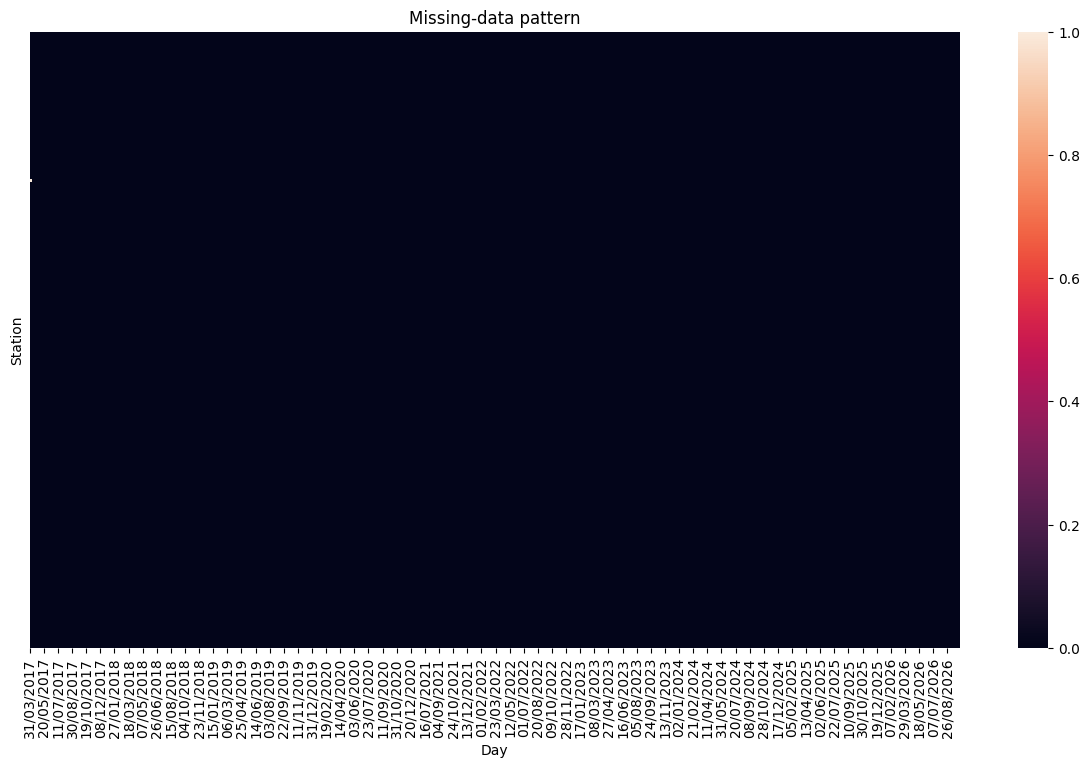

In [60]:
levels_avg = df_avg_clean.iloc[:, 3:]
levels_min = df_min_clean.iloc[:, 3:]
levels_max = df_max_clean.iloc[:, 3:]
levels_interp_avg = levels_avg.interpolate(axis=1, method="linear")
levels_interp_min = levels_min.interpolate(axis=1, method="linear")
levels_interp_max = levels_max.interpolate(axis=1, method="linear")
df_avg_clean = pd.concat([df_avg_clean.iloc[:, :3], levels_interp_avg], axis=1)
df_min_clean = pd.concat([df_min_clean.iloc[:, :3], levels_interp_min], axis=1)
df_max_clean = pd.concat([df_max_clean.iloc[:, :3], levels_interp_max], axis=1)


plt.figure(figsize=(15,8))
sns.heatmap(levels_interp_avg.isna(), cbar=True, yticklabels=False)
plt.xlabel("Day")
plt.ylabel("Station")
plt.title("Missing-data pattern")
plt.show()

# Model Fitting and Tuning

*In this section you should detail and motivate your choice of model and describe the process used to refine, tune, and fit that model. You are encouraged to explore different models but you should NOT include a detailed narrative or code of all of these attempts. At most this section should very briefly mention the methods explored and why they were rejected - most of your effort should go into describing the final model you are using and your process for tuning and validating it.*

*This section should include the full implementation of your final model, including all necessary validation. All displayed figures should be described and referenced in the text.*

*You should also include a baseline model of your choice and provide a comparison of your model with the baseline model on the test data. You should briefly describe the baseline model considered.*

# Interpretation, Discussion & Conclusions

*In this section you should provide a general overview of your final clustering and of your final supervised learning model, its performance, and reliability. You should discuss what the implications of your models are in terms of the included features, estimated parameters and relationships, predictive performance, and anything else you think is relevant.*

*This should be written with a target audience of a government official, who understands the monitoring of river levels but may only have university level mathematics (not necessarily postgraduate statistics or machine learning). Your goal should be to highlight to this audience how your model can useful. You should also discuss potential limitations or directions of future improvement of your model.*

*Finally, you should include recommendations on factors that may influence the classification of flood events OR the prediction of future water levels (depending on which question you are answering), which may be useful for the government officials to improve their understanding of floods or water level forecasting, and potentially assist in the development of effective river management and interventions.*

*Keep in mind that a negative result, i.e. a model that does not work well predictively, that is well explained and justified in terms of why it failed will likely receive higher marks than a model with strong predictive performance but with poor or incorrect explanations / justifications.*

# Generative AI statement

*Include a statement on if and how generative AI was used in the project and report.*

# References

*Include a list of all references cited in the text.*

In [1]:
# Run the following to render to PDF
!jupyter nbconvert --to pdf project.ipynb

[NbConvertApp] Converting notebook project.ipynb to pdf
[NbConvertApp] Writing 29863 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '-quiet']
[NbConvertApp] Running bibtex 1 time: ['bibtex', 'notebook']
[NbConvertApp] WARNING | bibtex had problems, most likely because there were no citations
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 47131 bytes to project.pdf
